# Prova pratica 2 - Fit e diagnostica
### Scopo della prova
Analizzeremo un dataset già acquisito mediante un fit pesato ai minimi quadrati (`data.csv` di *Attività 1*). L'obiettivo è stimare i parametri identificabili del modello fisico, ricavarne le relative incertezze e la matrice di correlazione, e valutare l'affidabilità della stima mediante l'analisi dei residui normalizzati (*pull*), del $\chi^2$ ridotto e del *$p$-value*.

### Modello fisico
La funzione teorica che descrive l'intensità luminosa del pattern di frange di interferenza e diffrazione costituita di un fondo uniforme è:
$$ f(x) = B + I_0 \left[ \frac{\sin(k a x)}{k a x} \right]^2 \cos^2(k d x) $$

In una singola acquisizione, le grandezze fisiche $k, a, d$ non sono identificabili separatamente, ma determinano unicamente le combinazioni:
$$ \alpha = k a, \quad \delta = k d $$

Il modello parametrizzato utilizzato per il fit è dunque:
$$ f(x; B, I_0, \alpha, \delta) = B + I_0 \left[ \frac{\sin(\alpha x)}{\alpha x} \right]^2 \cos^2(\delta x) $$
con i vincoli fisici $B \ge 0$, $I_0 \ge 0$, $\alpha > 0$ e $\delta > 0$.

In [5]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2 

def E(x, alpha):
    return  np.sinc(alpha*x/np.pi)**2

def C(x, delta):
    return np.cos(delta*x)**2

def mu(x, B, I, alpha, delta):
    return B + I*E(x, alpha)*C(x, delta)

data = np.genfromtxt(
    "data.csv",
    delimiter=",",
    names=True
)

x = data["x"]
y = data["y"]
sigma_y = data["sigma_y"]

### Attività 1: Caricamento e controllo dei dati
In questa prima sezione definiamo il modello teorico dell'esperimento, costituito dall'intensità di un pattern di interferenza e diffrazione costituito di un fondo costante. Il numero medio atteso di conteggi è descritto dalla funzione:
$$ \mu(x) = B + I_0 \left[ \frac{\sin(\alpha x)}{\alpha x} \right]^2 \cos^2(\delta x) $$

Successivamente carichiamo i dati dal file `data.csv`, generato tramite una simulazione Monte Carlo (*Attività 1*), e verifichiamo la compatibilità della lunghezza dei dati.

In [7]:
def size_comparison (data):
    return (len(data["x"])==len(data["y"]) and len(data["y"])==len(data["sigma_y"]))

print("\n==============================================================")
print("Compatibilità lunghezza dei dati: ",size_comparison(data))
print("Numero di conteggi: ", np.floor(np.sum(y)))
print("Intervallo di x : ", abs(x[0]-x[-1]), '\n')


Compatibilità lunghezza dei dati:  True
Numero di conteggi:  13588.0
Intervallo di x :  10.0 



### Attività 2: Stime iniziali e bounds
Per garantire la convergenza dell'algoritmo di ottimizzazione, è necessario fornire delle stime iniziali (`p0`) ragionevoli per i parametri del modello.
*   **Fondo ($B_0$)**: Stimato valutando la media dei valori misurati agli estremi della distribuzione spaziale.
*   **Intensità ($I_0$)**: Ricavata per differenza tra il picco massimo misurato e la stima del fondo.
*   **Frequenza delle frange ($\delta_0$) e larghezza dell'inviluppo ($\alpha_0$)**: Valutate geometricamente tramite analisi grafica delle distanze tra i massimi e la posizione dei minimi.

Vengono inoltre imposti dei limiti (*bounds*) fisicamente sensati (es. valori non negativi) entro cui l'algoritmo può cercare la soluzione ottimale.

In [8]:
B0 = (y[0] + y[-1])/2
I0 = np.max(y) - B0
delta0 = np.pi/0.6
alpha0 = np.pi/3.5

lower = [0.0, 0.0, 0.10, 1]
upper = [np.inf, np.inf, 3.0, 12.0]
p0 = [B0, I0, alpha0, delta0]

print(f"Parametri iniziali: B0={float(p0[0]):.4f}, I0={float(p0[1]):.4f}, alpha0={float(p0[2]):.4f}, delta0={float(p0[3]):.4f}")
print(f"Lower bounds: B0_inf={float(lower[0]):.4f}, I0_inf={float(lower[1]):.4f}, alpha0_inf={float(lower[2]):.4f}, delta0_inf={float(lower[3]):.4f}")
print(f"Upper bounds: B0_sup={float(upper[0]):.4f}, I0_sup={float(upper[1]):.4f}, alpha0_sup={float(upper[2]):.4f}, delta0_sup={float(upper[3]):.4f}\n")

Parametri iniziali: B0=27.9847, I0=393.1217, alpha0=0.8976, delta0=5.2360
Lower bounds: B0_inf=0.0000, I0_inf=0.0000, alpha0_inf=0.1000, delta0_inf=1.0000
Upper bounds: B0_sup=inf, I0_sup=inf, alpha0_sup=3.0000, delta0_sup=12.0000



### Attività 3: Fit pesato
Eseguiamo il fit ai minimi quadrati utilizzando la libreria `scipy.optimize`. 

A partire dalla matrice di covarianza restituita dalla procedura, calcoliamo le incertezze standard sui parametri ottimizzati e la relativa matrice di correlazione per valutare le dipendenze tra i parametri del modello.

Parametro B stimato:  20.0219  +/-  0.0114
Parametro I stimato:  399.9934  +/-  0.1125
Parametro alpha stimato:  0.9001  +/-  0.0002
Parametro delta stimato:  5.1998  +/-  0.0001



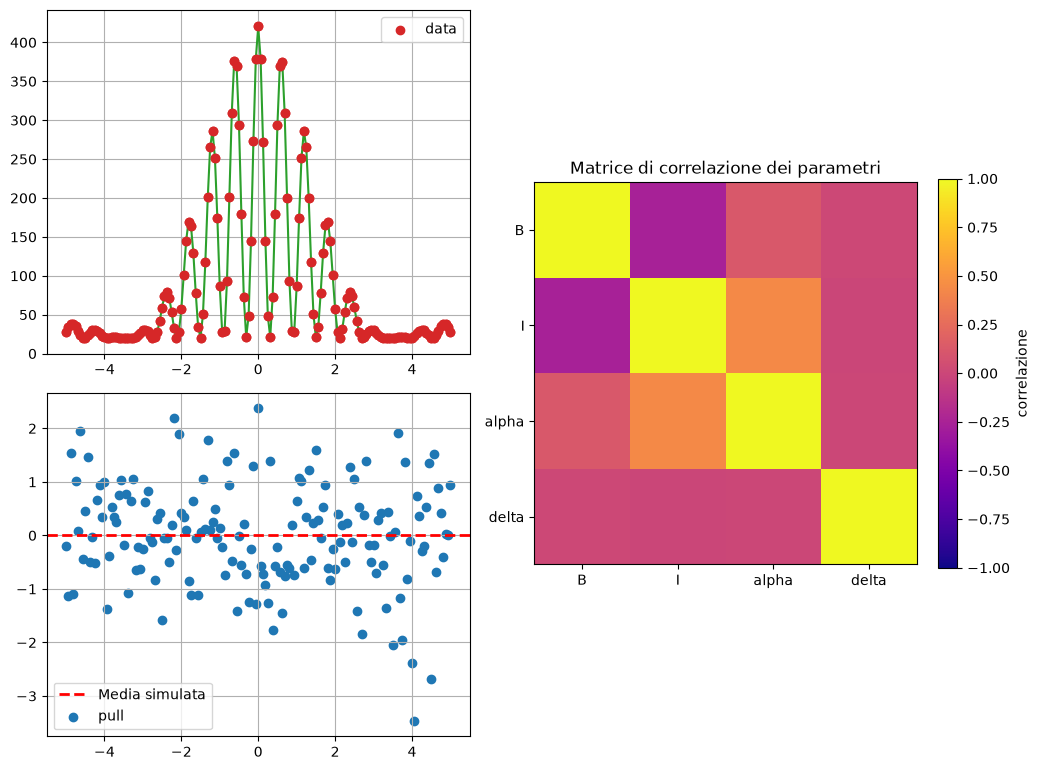

In [13]:
popt, pcov = curve_fit(
    mu, x, y,
    p0=p0,
    sigma=sigma_y,
    absolute_sigma=True,
    bounds=(lower, upper),
    maxfev=10000000
)

B_hat = popt[0]
I_hat = popt[1]
alpha_hat = popt[2]
delta_hat = popt[3]

sigma_y_hat = np.sqrt(np.diagonal(pcov))

den = np.sqrt(np.outer(np.diagonal(pcov),np.diagonal(pcov)))
corr = pcov / den

print("Parametro B stimato: ",f"{B_hat:.4f}", " +/- ",f"{sigma_y_hat[0]:.4f}")
print("Parametro I stimato: ",f"{I_hat:.4f}", " +/- ",f"{sigma_y_hat[1]:.4f}")
print("Parametro alpha stimato: ",f"{alpha_hat:.4f}", " +/- ",f"{sigma_y_hat[2]:.4f}")
print("Parametro delta stimato: ",f"{delta_hat:.4f}", " +/- ",f"{sigma_y_hat[3]:.4f}\n")

layout = """
AC
BC
"""

fig, axes = plt.subplot_mosaic(layout, figsize=(10.5, 7.8))
axes['A'].scatter(x, y, color="tab:red", label="data")
axes['A'].errorbar(x, y, sigma_y, fmt='o', color="tab:red")
axes['A'].grid(True)
axes['A'].legend()
axes['A'].plot(x, mu(x, B_hat, I_hat, alpha_hat, delta_hat), color="tab:green", label="fit")

im = axes['C'].imshow(corr, vmin=-1, vmax=1, cmap="plasma")
fig.colorbar(im, ax=axes['C'], fraction=0.046, shrink=1.0, label="correlazione")
axes['C'].set_xticks([0, 1, 2, 3], ["B", "I", "alpha", "delta"])
axes['C'].set_yticks([0, 1, 2, 3], ["B", "I", "alpha", "delta"])
axes['C'].set_title("Matrice di correlazione dei parametri")

res = data["y"] - mu(x, B_hat, I_hat, alpha_hat, delta_hat)
pull = res / sigma_y
chi2_obs = np.sum(pull**2)
dof = len(data) - len(p0)
chi2_red_obs = chi2_obs / dof

p_value = chi2.sf(chi2_obs, dof)

axes['B'].axhline(0, color="red", linestyle="--", linewidth=2, label="Media simulata")
axes['B'].grid(True)
axes['B'].scatter(x, pull, label="pull")
axes['B'].legend()

plt.tight_layout()
plt.show()

### Attività 4: Diagnostica del fit
Per valutare la validità e compatibilità del modello calcoliamo:
*   I **residui normalizzati (*Pull*)**: $r_i / \sigma_i$
*   Il **$\chi^2$ ridotto** e il ***p-value*** associato per la verifica statistica dell'ipotesi.

Infine generiamo la rappresentazione grafica della stima e la diagnostica: il grafico dei dati sovrapposti al fit, l'andamento dei pull per evidenziare eventuali deviazioni sistematiche e la mappa di colore per la matrice di correlazione.

In [14]:
print(f"Chi2_red_obs = {float(chi2_red_obs):.4f}")
print(f"p value = {float(p_value):.4f}")
print("==============================================================\n")

Chi2_red_obs = 0.9597
p value = 0.6273

